In [1]:
# Confirm which Python interpreter is running the current notebook kernel.
import sys

print(sys.executable)

/Users/zaamine/Desktop/Amine/Training/Kaggle/Corporacion Favorita/retail-demand-forecasting-platform-aws/.venv/bin/python


# Forecasting Baseline and Backtesting

This notebook establishes the first forecasting benchmark and the temporal
evaluation framework for the retail demand forecasting platform.

Objectives:

- define a leakage-safe temporal train/validation split;
- implement a weekly seasonal-naive baseline;
- evaluate forecasts using WAPE, MAE, RMSE, and normalized bias;
- analyze forecast accuracy across the 14-day horizon;
- extend the evaluation to multiple historical forecast origins through
  rolling backtesting.

The primary forecasting setup is:

- grain: `store × product family × day`;
- forecast horizon: 14 days;
- forecast refresh cadence: daily;
- primary metric: WAPE;
- secondary metrics: MAE, RMSE, and normalized bias.

In [2]:
from datetime import date

import pandas as pd


# Define the operational forecasting horizon used throughout the project.
FORECAST_HORIZON = 14

# Use the latest complete 14-day window as the initial holdout period.
FORECAST_ORIGIN = pd.Timestamp("2017-08-01")
VALIDATION_START = FORECAST_ORIGIN + pd.Timedelta(days=1)
VALIDATION_END = FORECAST_ORIGIN + pd.Timedelta(days=FORECAST_HORIZON)

print(f"Forecast origin:   {FORECAST_ORIGIN.date()}")
print(f"Validation start:  {VALIDATION_START.date()}")
print(f"Validation end:    {VALIDATION_END.date()}")

Forecast origin:   2017-08-01
Validation start:  2017-08-02
Validation end:    2017-08-15


In [3]:
import json
import subprocess
import time

GLUE_DATABASE = "retail_demand_forecasting_raw"
CURATED_DATABASE = "retail_demand_forecasting_curated"

ATHENA_OUTPUT = (
    "s3://retail-demand-forecasting-platform-aws-zaamine/"
    "artifacts/athena-query-results/notebook/"
)


def run_athena_query(query):
    """Run an Athena query and return the result as a pandas DataFrame."""

    start_result = subprocess.run(
        [
            "aws",
            "athena",
            "start-query-execution",
            "--query-string",
            query,
            "--result-configuration",
            f"OutputLocation={ATHENA_OUTPUT}",
            "--output",
            "json",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    query_execution_id = json.loads(start_result.stdout)["QueryExecutionId"]

    while True:
        status_result = subprocess.run(
            [
                "aws",
                "athena",
                "get-query-execution",
                "--query-execution-id",
                query_execution_id,
                "--query",
                "QueryExecution.Status.State",
                "--output",
                "text",
            ],
            capture_output=True,
            text=True,
            check=True,
        )

        status = status_result.stdout.strip()

        if status in {"SUCCEEDED", "FAILED", "CANCELLED"}:
            break

        time.sleep(1)

    if status != "SUCCEEDED":
        raise RuntimeError(
            f"Athena query ended with status: {status}"
        )

    result = subprocess.run(
        [
            "aws",
            "athena",
            "get-query-results",
            "--query-execution-id",
            query_execution_id,
            "--output",
            "json",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    payload = json.loads(result.stdout)
    rows = payload["ResultSet"]["Rows"]

    columns = [
        item.get("VarCharValue")
        for item in rows[0]["Data"]
    ]

    data = [
        [
            item.get("VarCharValue")
            for item in row["Data"]
        ]
        for row in rows[1:]
    ]

    return pd.DataFrame(data, columns=columns)

In [4]:
from pathlib import Path


# Locate the repository root independently of the notebook's launch directory.
current_path = Path.cwd()

for path in [current_path, *current_path.parents]:
    if (path / "pyproject.toml").exists():
        PROJECT_ROOT = path
        break
else:
    raise RuntimeError("Project root not found.")

print("Project root:", PROJECT_ROOT)

Project root: /Users/zaamine/Desktop/Amine/Training/Kaggle/Corporacion Favorita/retail-demand-forecasting-platform-aws


In [5]:
# Load a compact recent window from the validated curated layer.
# The baseline itself only needs the latest observed week at the forecast origin.
baseline_data = run_athena_query(
    """
    SELECT
        date,
        store_nbr,
        family,
        sales,
        onpromotion
    FROM retail_demand_forecasting_curated.stg_sales
    WHERE date BETWEEN DATE '2017-07-01' AND DATE '2017-08-15'
    ORDER BY date, store_nbr, family
    """
)

baseline_data["date"] = pd.to_datetime(baseline_data["date"])
baseline_data["sales"] = baseline_data["sales"].astype(float)
baseline_data["onpromotion"] = baseline_data["onpromotion"].astype(int)

print(baseline_data.shape)
display(baseline_data.head())

(81972, 5)


,date,store_nbr,family,sales,onpromotion
0,2017-07-01,1,AUTOMOTIVE,7.0,0
1,2017-07-01,1,BABY CARE,0.0,0
2,2017-07-01,1,BEAUTY,7.0,1
3,2017-07-01,1,BEVERAGES,2596.0,27
4,2017-07-01,1,BOOKS,0.0,0


In [6]:
# Verify that the evaluation window preserves the expected forecasting panel.
window_summary = pd.DataFrame(
    {
        "min_date": [baseline_data["date"].min()],
        "max_date": [baseline_data["date"].max()],
        "stores": [baseline_data["store_nbr"].nunique()],
        "families": [baseline_data["family"].nunique()],
        "series": [
            baseline_data[["store_nbr", "family"]]
            .drop_duplicates()
            .shape[0]
        ],
    }
)

display(window_summary)

,min_date,max_date,stores,families,series
0,2017-07-01,2017-08-15,54,33,1782


In [7]:
import numpy as np


# Build the 14-day forecast calendar from a single forecast origin.
forecast_calendar = pd.DataFrame(
    {
        "horizon": np.arange(1, FORECAST_HORIZON + 1),
    }
)

forecast_calendar["forecast_date"] = (
    FORECAST_ORIGIN
    + pd.to_timedelta(forecast_calendar["horizon"], unit="D")
)

# Map each future date to the latest same-weekday observation available
# at the forecast origin. Week 1 and week 2 therefore reuse the same
# seven historical observations.
forecast_calendar["source_date"] = (
    forecast_calendar["forecast_date"]
    - pd.to_timedelta(
        7 * np.ceil(forecast_calendar["horizon"] / 7).astype(int),
        unit="D",
    )
)

display(forecast_calendar)

,horizon,forecast_date,source_date
0,1,2017-08-02,2017-07-26
1,2,2017-08-03,2017-07-27
2,3,2017-08-04,2017-07-28
3,4,2017-08-05,2017-07-29
4,5,2017-08-06,2017-07-30
5,6,2017-08-07,2017-07-31
6,7,2017-08-08,2017-08-01
7,8,2017-08-09,2017-07-26
8,9,2017-08-10,2017-07-27
9,10,2017-08-11,2017-07-28


In [8]:
# Ensure that every baseline prediction uses information available
# no later than the forecast origin.
assert (
    forecast_calendar["source_date"] <= FORECAST_ORIGIN
).all()

print("All seasonal-naive source dates are available at the forecast origin.")

All seasonal-naive source dates are available at the forecast origin.


In [9]:
# Extract the seven historical dates used by the seasonal-naive baseline.
source_dates = forecast_calendar["source_date"].unique()

seasonal_history = baseline_data.loc[
    baseline_data["date"].isin(source_dates),
    ["date", "store_nbr", "family", "sales"],
].copy()

seasonal_history = seasonal_history.rename(
    columns={
        "date": "source_date",
        "sales": "prediction",
    }
)

print(seasonal_history.shape)
display(seasonal_history.head())

(12474, 4)


,source_date,store_nbr,family,prediction
44550,2017-07-26,1,AUTOMOTIVE,2.0
44551,2017-07-26,1,BABY CARE,0.0
44552,2017-07-26,1,BEAUTY,3.0
44553,2017-07-26,1,BEVERAGES,2242.0
44554,2017-07-26,1,BOOKS,0.0


In [10]:
# The source week must contain one observation per series and weekday.
EXPECTED_SOURCE_ROWS = 7 * 1_782

assert len(seasonal_history) == EXPECTED_SOURCE_ROWS
assert seasonal_history["prediction"].notna().all()

print("Seasonal history contains all expected source observations.")

Seasonal history contains all expected source observations.


In [11]:
# Each source weekday is reused twice because the forecast horizon spans two weeks.
assert forecast_calendar["source_date"].value_counts().eq(2).all()

# Each source date must contain one observation for every store-family series.
assert seasonal_history["source_date"].value_counts().eq(1_782).all()

In [12]:
# Replicate each historical weekday across every future horizon that reuses it.
seasonal_naive_forecasts = forecast_calendar.merge(
    seasonal_history,
    on="source_date",
    how="left",
    validate="many_to_many",
)

seasonal_naive_forecasts = seasonal_naive_forecasts[
    [
        "forecast_date",
        "horizon",
        "store_nbr",
        "family",
        "source_date",
        "prediction",
    ]
].sort_values(
    ["forecast_date", "store_nbr", "family"]
)

print(seasonal_naive_forecasts.shape)
display(seasonal_naive_forecasts.head())

(24948, 6)


,forecast_date,horizon,store_nbr,family,source_date,prediction
0,2017-08-02,1,1,AUTOMOTIVE,2017-07-26,2.0
1,2017-08-02,1,1,BABY CARE,2017-07-26,0.0
2,2017-08-02,1,1,BEAUTY,2017-07-26,3.0
3,2017-08-02,1,1,BEVERAGES,2017-07-26,2242.0
4,2017-08-02,1,1,BOOKS,2017-07-26,0.0


In [13]:
# Validate that every series receives one prediction for every forecast horizon.
EXPECTED_FORECAST_ROWS = FORECAST_HORIZON * 1_782

assert len(seasonal_naive_forecasts) == EXPECTED_FORECAST_ROWS
assert seasonal_naive_forecasts["prediction"].notna().all()

print("Seasonal-naive forecasts generated for all series and horizons.")

Seasonal-naive forecasts generated for all series and horizons.


In [14]:
# Inspect one representative series to make the multi-horizon logic explicit.
example_forecast = seasonal_naive_forecasts.loc[
    (seasonal_naive_forecasts["store_nbr"] == 1)
    & (seasonal_naive_forecasts["family"] == "BEVERAGES")
]

display(example_forecast)

,forecast_date,horizon,store_nbr,family,source_date,prediction


In [15]:
# Inspect inferred pandas types after loading data from Athena.
print(seasonal_naive_forecasts.dtypes)

print(
    seasonal_naive_forecasts["store_nbr"]
    .head()
    .tolist()
)

forecast_date    datetime64[us]
horizon                   int64
store_nbr                   str
family                      str
source_date      datetime64[us]
prediction              float64
dtype: object
['1', '1', '1', '1', '1']


In [16]:
# Inspect one representative series to make the multi-horizon logic explicit.
example_forecast = seasonal_naive_forecasts.loc[
    (seasonal_naive_forecasts["store_nbr"] == "1")
    & (seasonal_naive_forecasts["family"] == "BEVERAGES")
]

display(example_forecast)

,forecast_date,horizon,store_nbr,family,source_date,prediction
3,2017-08-02,1,1,BEVERAGES,2017-07-26,2242.0
1785,2017-08-03,2,1,BEVERAGES,2017-07-27,2002.0
3567,2017-08-04,3,1,BEVERAGES,2017-07-28,2358.0
5349,2017-08-05,4,1,BEVERAGES,2017-07-29,2161.0
7131,2017-08-06,5,1,BEVERAGES,2017-07-30,1212.0
8913,2017-08-07,6,1,BEVERAGES,2017-07-31,2414.0
10695,2017-08-08,7,1,BEVERAGES,2017-08-01,2627.0
12477,2017-08-09,8,1,BEVERAGES,2017-07-26,2242.0
14259,2017-08-10,9,1,BEVERAGES,2017-07-27,2002.0
16041,2017-08-11,10,1,BEVERAGES,2017-07-28,2358.0


In [17]:
# Extract the realized sales used only for post-forecast evaluation.
validation_actuals = baseline_data.loc[
    baseline_data["date"].between(
        VALIDATION_START,
        VALIDATION_END,
    ),
    ["date", "store_nbr", "family", "sales"],
].copy()

validation_actuals = validation_actuals.rename(
    columns={
        "date": "forecast_date",
        "sales": "actual",
    }
)

print(validation_actuals.shape)
display(validation_actuals.head())

(24948, 4)


,forecast_date,store_nbr,family,actual
57024,2017-08-02,1,AUTOMOTIVE,4.0
57025,2017-08-02,1,BABY CARE,0.0
57026,2017-08-02,1,BEAUTY,2.0
57027,2017-08-02,1,BEVERAGES,2645.0
57028,2017-08-02,1,BOOKS,0.0


In [18]:
# Attach realized sales after forecasts have been generated.
# Actual values are used only for evaluation and never as model inputs.
baseline_evaluation = seasonal_naive_forecasts.merge(
    validation_actuals,
    on=["forecast_date", "store_nbr", "family"],
    how="left",
    validate="one_to_one",
)

assert len(baseline_evaluation) == EXPECTED_FORECAST_ROWS
assert baseline_evaluation["actual"].notna().all()

display(baseline_evaluation.head())

,forecast_date,horizon,store_nbr,family,source_date,prediction,actual
0,2017-08-02,1,1,AUTOMOTIVE,2017-07-26,2.0,4.0
1,2017-08-02,1,1,BABY CARE,2017-07-26,0.0,0.0
2,2017-08-02,1,1,BEAUTY,2017-07-26,3.0,2.0
3,2017-08-02,1,1,BEVERAGES,2017-07-26,2242.0,2645.0
4,2017-08-02,1,1,BOOKS,2017-07-26,0.0,0.0


## Metrics

In [19]:
# Compute signed and absolute forecast errors for each series-horizon observation.
baseline_evaluation["error"] = (
    baseline_evaluation["prediction"]
    - baseline_evaluation["actual"]
)

baseline_evaluation["absolute_error"] = (
    baseline_evaluation["error"].abs()
)

baseline_evaluation["squared_error"] = (
    baseline_evaluation["error"] ** 2
)

display(baseline_evaluation.head())

,forecast_date,horizon,store_nbr,family,source_date,prediction,actual,error,absolute_error,squared_error
0,2017-08-02,1,1,AUTOMOTIVE,2017-07-26,2.0,4.0,-2.0,2.0,4.0
1,2017-08-02,1,1,BABY CARE,2017-07-26,0.0,0.0,0.0,0.0,0.0
2,2017-08-02,1,1,BEAUTY,2017-07-26,3.0,2.0,1.0,1.0,1.0
3,2017-08-02,1,1,BEVERAGES,2017-07-26,2242.0,2645.0,-403.0,403.0,162409.0
4,2017-08-02,1,1,BOOKS,2017-07-26,0.0,0.0,0.0,0.0,0.0


In [20]:
# Compute global forecasting metrics across all series and horizons.
mae = baseline_evaluation["absolute_error"].mean()

rmse = np.sqrt(
    baseline_evaluation["squared_error"].mean()
)

wape = (
    baseline_evaluation["absolute_error"].sum()
    / baseline_evaluation["actual"].sum()
)

normalized_bias = (
    baseline_evaluation["error"].sum()
    / baseline_evaluation["actual"].sum()
)

baseline_metrics = pd.DataFrame(
    {
        "metric": ["MAE", "RMSE", "WAPE", "Normalized Bias"],
        "value": [mae, rmse, wape, normalized_bias],
    }
)

display(baseline_metrics)

,metric,value
0,MAE,106.475958
1,RMSE,380.031724
2,WAPE,0.232102
3,Normalized Bias,0.095004


## Metrics by temporal horizon

In [21]:
# Evaluate forecasting performance separately at each prediction horizon.
horizon_metrics = (
    baseline_evaluation
    .groupby("horizon")
    .apply(
        lambda group: pd.Series(
            {
                "MAE": group["absolute_error"].mean(),
                "RMSE": np.sqrt(group["squared_error"].mean()),
                "WAPE": (
                    group["absolute_error"].sum()
                    / group["actual"].sum()
                ),
                "Normalized Bias": (
                    group["error"].sum()
                    / group["actual"].sum()
                ),
            }
        ),
        include_groups=False,
    )
    .reset_index()
)

display(horizon_metrics)

,horizon,MAE,RMSE,WAPE,Normalized Bias
0,1,138.053359,452.335249,0.255010,-0.232255
1,2,75.361040,256.386372,0.184452,-0.093698
2,3,74.993449,254.392247,0.161443,0.008848
3,4,83.961559,290.008355,0.154935,0.068984
4,5,89.679820,355.475570,0.152263,0.070690
5,6,74.784662,257.261265,0.167112,0.110841
6,7,162.047198,513.201207,0.402315,0.377228
7,8,62.284426,190.434282,0.151185,0.008872
8,9,70.037249,282.680763,0.191601,0.012992
9,10,99.383874,314.769259,0.214312,0.010559


In [22]:
# Add percentage-formatted columns for easier interpretation.
horizon_metrics["WAPE_pct"] = (
    100 * horizon_metrics["WAPE"]
)

horizon_metrics["Normalized_Bias_pct"] = (
    100 * horizon_metrics["Normalized Bias"]
)

display(
    horizon_metrics[
        [
            "horizon",
            "MAE",
            "RMSE",
            "WAPE_pct",
            "Normalized_Bias_pct",
        ]
    ]
)

,horizon,MAE,RMSE,WAPE_pct,Normalized_Bias_pct
0,1,138.053359,452.335249,25.500987,-23.225477
1,2,75.361040,256.386372,18.445157,-9.369813
2,3,74.993449,254.392247,16.144268,0.884780
3,4,83.961559,290.008355,15.493474,6.898380
4,5,89.679820,355.475570,15.226339,7.068998
5,6,74.784662,257.261265,16.711238,11.084108
6,7,162.047198,513.201207,40.231491,37.722779
7,8,62.284426,190.434282,15.118492,0.887211
8,9,70.037249,282.680763,19.160099,1.299215
9,10,99.383874,314.769259,21.431231,1.055934


## Rolling-origin backtest

In [23]:
# Define non-overlapping historical forecast origins for rolling backtesting.
BACKTEST_ORIGINS = pd.to_datetime(
    [
        "2017-05-23",
        "2017-06-06",
        "2017-06-20",
        "2017-07-04",
        "2017-07-18",
        "2017-08-01",
    ]
)

# Load only the history required by the earliest seasonal-naive source date
# and the latest validation target date.
backtest_data = run_athena_query(
    """
    SELECT
        date,
        store_nbr,
        family,
        sales
    FROM retail_demand_forecasting_curated.stg_sales
    WHERE date BETWEEN DATE '2017-05-17' AND DATE '2017-08-15'
    ORDER BY date, store_nbr, family
    """
)

# Normalize Athena outputs to the pandas types required for forecasting.
backtest_data["date"] = pd.to_datetime(backtest_data["date"])
backtest_data["store_nbr"] = backtest_data["store_nbr"].astype("string")
backtest_data["sales"] = backtest_data["sales"].astype(float)

print(backtest_data.shape)
print(
    backtest_data["date"].min(),
    backtest_data["date"].max(),
)

(162162, 4)
2017-05-17 00:00:00 2017-08-15 00:00:00


In [24]:
def evaluate_seasonal_naive_at_origin(
    data,
    forecast_origin,
    forecast_horizon=14,
):
    """Generate and evaluate leakage-safe weekly seasonal-naive forecasts."""

    forecast_origin = pd.Timestamp(forecast_origin)

    # Build the future horizons associated with this historical forecast origin.
    forecast_calendar = pd.DataFrame(
        {
            "horizon": np.arange(1, forecast_horizon + 1),
        }
    )

    forecast_calendar["forecast_date"] = (
        forecast_origin
        + pd.to_timedelta(
            forecast_calendar["horizon"],
            unit="D",
        )
    )

    # Map each future date to the latest same-weekday observation that was
    # already available when the forecast was produced.
    forecast_calendar["source_date"] = (
        forecast_calendar["forecast_date"]
        - pd.to_timedelta(
            7
            * np.ceil(
                forecast_calendar["horizon"] / 7
            ).astype(int),
            unit="D",
        )
    )

    # Explicitly enforce the point-in-time constraint.
    assert (
        forecast_calendar["source_date"]
        <= forecast_origin
    ).all()

    # Extract the historical observations used by the seasonal-naive model.
    seasonal_history = data.loc[
        data["date"].isin(
            forecast_calendar["source_date"]
        ),
        ["date", "store_nbr", "family", "sales"],
    ].copy()

    seasonal_history = seasonal_history.rename(
        columns={
            "date": "source_date",
            "sales": "prediction",
        }
    )

    # Expand each historical weekday to every future horizon that reuses it.
    forecasts = forecast_calendar.merge(
        seasonal_history,
        on="source_date",
        how="left",
        validate="many_to_many",
    )

    # Extract realized future sales only after forecasts have been generated.
    actuals = data.loc[
        data["date"].between(
            forecast_origin + pd.Timedelta(days=1),
            forecast_origin
            + pd.Timedelta(days=forecast_horizon),
        ),
        ["date", "store_nbr", "family", "sales"],
    ].copy()

    actuals = actuals.rename(
        columns={
            "date": "forecast_date",
            "sales": "actual",
        }
    )

    # Match predictions with realized values for post-forecast evaluation.
    evaluation = forecasts.merge(
        actuals,
        on=["forecast_date", "store_nbr", "family"],
        how="left",
        validate="one_to_one",
    )

    evaluation["forecast_origin"] = forecast_origin

    # Compute error components once so all evaluation metrics use
    # exactly the same convention.
    evaluation["error"] = (
        evaluation["prediction"]
        - evaluation["actual"]
    )

    evaluation["absolute_error"] = (
        evaluation["error"].abs()
    )

    evaluation["squared_error"] = (
        evaluation["error"] ** 2
    )

    return evaluation

In [25]:
# Simulate the same forecasting process independently at each historical origin.
backtest_folds = [
    evaluate_seasonal_naive_at_origin(
        data=backtest_data,
        forecast_origin=origin,
        forecast_horizon=FORECAST_HORIZON,
    )
    for origin in BACKTEST_ORIGINS
]

rolling_backtest = pd.concat(
    backtest_folds,
    ignore_index=True,
)

print(rolling_backtest.shape)
display(rolling_backtest.head())

(149688, 11)


,horizon,forecast_date,source_date,store_nbr,family,prediction,actual,forecast_origin,error,absolute_error,squared_error
0,1,2017-05-24,2017-05-17,1,AUTOMOTIVE,2.0,7.0,2017-05-23,-5.0,5.0,25.0
1,1,2017-05-24,2017-05-17,1,BABY CARE,0.0,0.0,2017-05-23,0.0,0.0,0.0
2,1,2017-05-24,2017-05-17,1,BEAUTY,5.0,1.0,2017-05-23,4.0,4.0,16.0
3,1,2017-05-24,2017-05-17,1,BEVERAGES,2374.0,2611.0,2017-05-23,-237.0,237.0,56169.0
4,1,2017-05-24,2017-05-17,1,BOOKS,1.0,1.0,2017-05-23,0.0,0.0,0.0


In [26]:
# Validate that every backtest origin contains one forecast per series and horizon.
EXPECTED_BACKTEST_ROWS = (
    len(BACKTEST_ORIGINS)
    * FORECAST_HORIZON
    * 1_782
)

assert len(rolling_backtest) == EXPECTED_BACKTEST_ROWS

# Every forecast must have both a prediction and a realized target.
assert rolling_backtest["prediction"].notna().all()
assert rolling_backtest["actual"].notna().all()

print("Rolling backtest contains all expected forecasts and actuals.")

Rolling backtest contains all expected forecasts and actuals.


In [27]:
# Compute aggregate baseline performance across all backtest origins and horizons.
rolling_mae = rolling_backtest["absolute_error"].mean()

rolling_rmse = np.sqrt(
    rolling_backtest["squared_error"].mean()
)

rolling_wape = (
    rolling_backtest["absolute_error"].sum()
    / rolling_backtest["actual"].sum()
)

rolling_bias = (
    rolling_backtest["error"].sum()
    / rolling_backtest["actual"].sum()
)

rolling_global_metrics = pd.DataFrame(
    {
        "metric": [
            "MAE",
            "RMSE",
            "WAPE",
            "Normalized Bias",
        ],
        "value": [
            rolling_mae,
            rolling_rmse,
            rolling_wape,
            rolling_bias,
        ],
    }
)

display(rolling_global_metrics)

,metric,value
0,MAE,91.679476
1,RMSE,354.460476
2,WAPE,0.191000
3,Normalized Bias,0.034743


### Performance by forecast origin

In [28]:
def summarize_forecast_metrics(data, group_columns):
    """Compute forecasting metrics for each requested evaluation group."""

    # Aggregate the components needed to derive all forecasting metrics.
    summary = (
        data
        .groupby(group_columns, as_index=False)
        .agg(
            MAE=("absolute_error", "mean"),
            mean_squared_error=("squared_error", "mean"),
            absolute_error_sum=("absolute_error", "sum"),
            error_sum=("error", "sum"),
            actual_sum=("actual", "sum"),
            observations=("actual", "size"),
        )
    )

    # RMSE gives additional weight to large individual forecast errors.
    summary["RMSE"] = np.sqrt(
        summary["mean_squared_error"]
    )

    # WAPE normalizes total absolute error by total realized demand.
    summary["WAPE"] = (
        summary["absolute_error_sum"]
        / summary["actual_sum"]
    )

    # Normalized bias identifies systematic over- or underforecasting.
    summary["Normalized Bias"] = (
        summary["error_sum"]
        / summary["actual_sum"]
    )

    return summary[
        group_columns
        + [
            "observations",
            "MAE",
            "RMSE",
            "WAPE",
            "Normalized Bias",
        ]
    ]

In [29]:
# Measure how baseline performance varies across historical forecast origins.
origin_metrics = summarize_forecast_metrics(
    rolling_backtest,
    group_columns=["forecast_origin"],
)

display(origin_metrics)

,forecast_origin,observations,MAE,RMSE,WAPE,Normalized Bias
0,2017-05-23,24948,90.967908,362.491247,0.179002,-0.056135
1,2017-06-06,24948,100.314817,401.993608,0.209758,0.142261
2,2017-06-20,24948,86.052668,339.087838,0.178059,-0.017866
3,2017-07-04,24948,93.163024,352.948417,0.197865,0.094178
4,2017-07-18,24948,73.102483,277.267648,0.152081,-0.038985
5,2017-08-01,24948,106.475958,380.031724,0.232102,0.095004


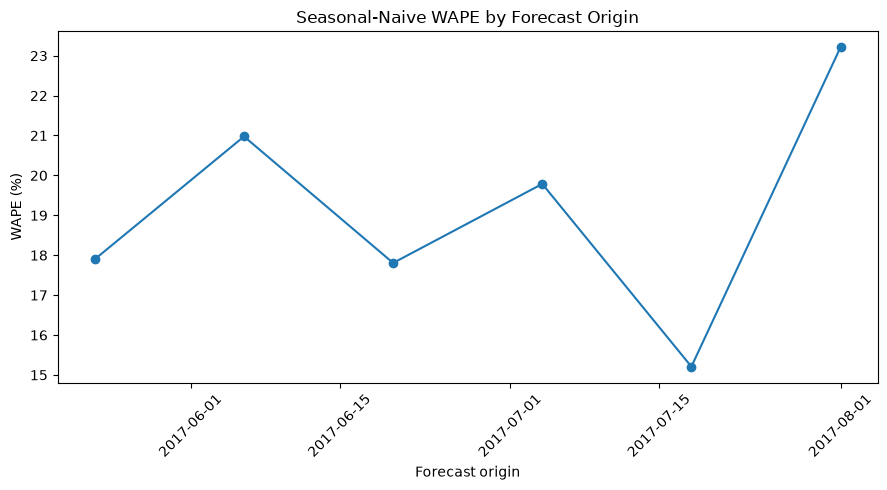

In [35]:
import matplotlib.pyplot as plt
from pathlib import Path


# Store forecasting figures in a versioned documentation directory.
FIGURES_DIR = PROJECT_ROOT / "docs" / "assets" / "forecasting"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# Visualize how baseline accuracy varies across historical forecast origins.
plt.figure(figsize=(9, 5))

plt.plot(
    origin_metrics["forecast_origin"],
    100 * origin_metrics["WAPE"],
    marker="o",
)

plt.xlabel("Forecast origin")
plt.ylabel("WAPE (%)")
plt.title("Seasonal-Naive WAPE by Forecast Origin")
plt.xticks(rotation=45)
plt.tight_layout()

# Save the figure before displaying it so the exact notebook output is reproducible.
plt.savefig(
    FIGURES_DIR / "seasonal_naive_wape_by_origin.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

### Interpretation

The seasonal-naive baseline is not equally accurate across historical periods.

WAPE ranges from approximately **15.2%** for the 2017-07-18 forecast origin
to **23.2%** for the 2017-08-01 origin. The initial August holdout is therefore
the most difficult of the six evaluated periods and would have provided an
overly pessimistic estimate of baseline performance if considered alone.

Across all six rolling backtest folds, the seasonal-naive baseline achieves a
global WAPE of approximately **19.1%**.

This temporal variability motivates evaluating future forecasting models across
multiple historical forecast origins rather than relying on a single holdout
period.

### Performance by forecast horizon

In [30]:
# Each origin must evaluate the same complete 14-day forecasting panel.
assert origin_metrics["observations"].eq(
    FORECAST_HORIZON * 1_782
).all()

In [31]:
# Measure forecast quality separately for each lead time across all origins.
rolling_horizon_metrics = summarize_forecast_metrics(
    rolling_backtest,
    group_columns=["horizon"],
)

display(rolling_horizon_metrics)

,horizon,observations,MAE,RMSE,WAPE,Normalized Bias
0,1,10692,80.038322,316.638845,0.173498,-0.045764
1,2,10692,66.370154,235.039179,0.176802,-0.009395
2,3,10692,82.785445,302.905278,0.178576,-0.005410
3,4,10692,99.224289,351.545347,0.183352,0.126283
4,5,10692,107.161834,404.954312,0.175122,0.079751
5,6,10692,74.663429,279.946325,0.169178,0.083366
6,7,10692,82.825501,318.213689,0.205184,0.127679
7,8,10692,62.353692,261.238936,0.144949,0.023322
8,9,10692,70.256219,261.718285,0.187847,-0.005726
9,10,10692,83.590888,293.410181,0.179381,-0.010557


### Horizon interpretation caveat

The six backtest origins are spaced exactly 14 days apart. Because 14 days
correspond to two full weeks, every forecast origin falls on the same weekday:
Tuesday.

As a consequence, each forecast horizon is always associated with the same
day of the week across all backtest folds:

- `h = 1` and `h = 8` always correspond to Wednesday;
- `h = 2` and `h = 9` always correspond to Thursday;
- ...
- `h = 5` and `h = 12` always correspond to Sunday;
- `h = 7` and `h = 14` always correspond to Tuesday.

This creates a confounding between **forecast lead time** and
**day-of-week difficulty**.

For example, the relatively high WAPE observed at `h = 12` cannot be
interpreted directly as evidence that forecasting 12 days ahead is inherently
more difficult. Since `h = 12` always corresponds to Sunday in this backtest,
the higher error could instead be caused by Sundays being intrinsically harder
to forecast.

The current horizon analysis therefore mixes two effects:

1. how far ahead the forecast is produced;
2. which day of the week is being forecast.

Comparing horizons `h` and `h + 7` partially controls for this issue because
both forecasts target the same weekday while differing by exactly one week of
lead time. For example, comparing `h = 5` with `h = 12` compares two Sunday
forecasts produced one week apart.

A denser rolling backtest with forecast origins occurring on different weekdays
would allow lead-time effects to be separated more clearly from day-of-week
effects. Such windows may overlap; this does not create leakage as long as each
forecast uses only information available at its own forecast origin, although
the resulting evaluation observations are more statistically dependent.

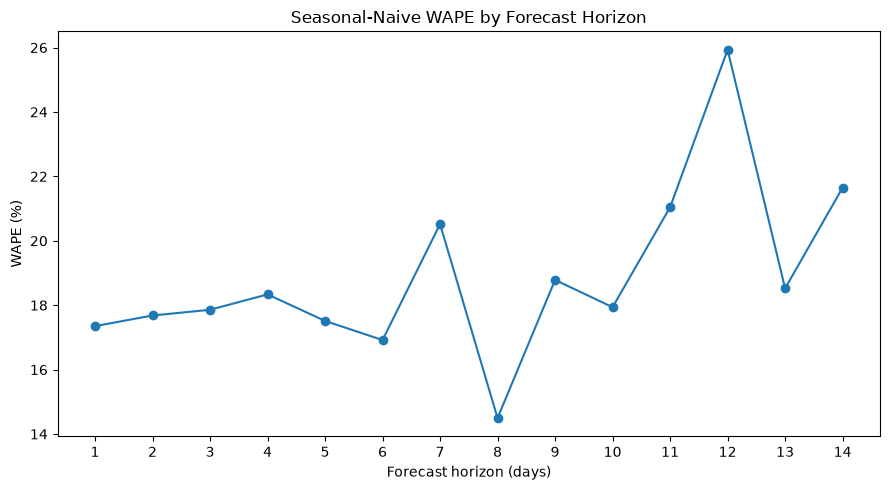

In [34]:
# Visualize the descriptive error profile across the 14 forecast horizons.
# Horizon effects must be interpreted jointly with weekday effects because
# all backtest origins currently fall on the same weekday.
plt.figure(figsize=(9, 5))

plt.plot(
    rolling_horizon_metrics["horizon"],
    100 * rolling_horizon_metrics["WAPE"],
    marker="o",
)

plt.xlabel("Forecast horizon (days)")
plt.ylabel("WAPE (%)")
plt.title("Seasonal-Naive WAPE by Forecast Horizon")
plt.xticks(range(1, FORECAST_HORIZON + 1))
plt.tight_layout()

# Persist the diagnostic figure for documentation and later comparison.
plt.savefig(
    FIGURES_DIR / "seasonal_naive_wape_by_horizon.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

### Interpretation

Forecast accuracy does not deteriorate monotonically with the forecast horizon.

The observed WAPE varies substantially across horizons, with particularly high
errors at some lead times such as `h = 12`. However, these differences cannot
be attributed purely to forecast distance because each horizon is also tied to
a fixed weekday in the current backtest design.

The horizon profile should therefore be interpreted as a **descriptive
diagnostic**, not as a clean estimate of the causal effect of forecast lead
time on accuracy.

Comparisons between `h` and `h + 7` are more informative because they hold the
target weekday constant while increasing the lead time by one week.

### Week 1 vs Week 2 same-weekday comparison

In [36]:
# Compare equivalent weekdays between the first and second forecast weeks.
# Pairing h with h + 7 holds the weekday constant while increasing lead time by one week.
week_1_metrics = rolling_horizon_metrics.loc[
    rolling_horizon_metrics["horizon"].between(1, 7),
    ["horizon", "WAPE", "Normalized Bias"],
].copy()

week_2_metrics = rolling_horizon_metrics.loc[
    rolling_horizon_metrics["horizon"].between(8, 14),
    ["horizon", "WAPE", "Normalized Bias"],
].copy()

# Align second-week horizons with their corresponding first-week weekday.
week_2_metrics["horizon"] = week_2_metrics["horizon"] - 7

weekday_horizon_comparison = week_1_metrics.merge(
    week_2_metrics,
    on="horizon",
    suffixes=("_week_1", "_week_2"),
    validate="one_to_one",
)

weekday_horizon_comparison["WAPE_change"] = (
    weekday_horizon_comparison["WAPE_week_2"]
    - weekday_horizon_comparison["WAPE_week_1"]
)

display(weekday_horizon_comparison)

,horizon,WAPE_week_1,Normalized Bias_week_1,WAPE_week_2,Normalized Bias_week_2,WAPE_change
0,1,0.173498,-0.045764,0.144949,0.023322,-0.028549
1,2,0.176802,-0.009395,0.187847,-0.005726,0.011045
2,3,0.178576,-0.005410,0.179381,-0.010557,0.000804
3,4,0.183352,0.126283,0.210404,0.038738,0.027052
4,5,0.175122,0.079751,0.259316,0.049983,0.084194
5,6,0.169178,0.083366,0.185217,0.003536,0.016040
6,7,0.205184,0.127679,0.216510,-0.008053,0.011327


## Baseline Summary

This notebook established the first leakage-safe forecasting benchmark for the
retail demand forecasting platform.

### Evaluation setup

- forecasting grain: `store × product family × day`;
- forecast horizon: 14 days;
- forecast refresh cadence: daily;
- baseline model: weekly seasonal naive (`m = 7`);
- primary metric: WAPE;
- secondary metrics: MAE, RMSE, and normalized bias;
- rolling backtest: 6 non-overlapping 14-day validation windows covering
  84 historical target days and 149,688 individual forecasts.

### Baseline performance

Across the rolling backtest, the weekly seasonal-naive model achieves:

- **WAPE: 19.10%**
- **MAE: 91.68**
- **RMSE: 354.46**
- **Normalized Bias: +3.47%**

The initial 2017-08-01 holdout produced a WAPE of 23.21%, making it the most
difficult of the six evaluated periods. This demonstrates why forecasting
performance should not be assessed from a single temporal holdout.

### Key findings

The seasonal-naive baseline provides a meaningful benchmark because it captures
weekly seasonality using only information available at each forecast origin.

Forecast accuracy varies substantially across historical periods, confirming
the importance of rolling-origin evaluation.

Performance also varies across forecast horizons. However, because all current
backtest origins fall on Tuesday, horizon and target weekday are confounded.
The horizon profile must therefore be treated as a descriptive diagnostic
rather than a clean estimate of the effect of forecast lead time.

Comparisons between `h` and `h + 7` are more informative because they hold the
target weekday constant while increasing the forecast lead time by one week.

### Benchmark for future models

Future forecasting models should be evaluated using the same leakage-safe
backtesting framework and compared against the seasonal-naive rolling WAPE of
**19.10%**.

A more complex model is valuable only if it improves forecasting performance
consistently across historical forecast origins, rather than on a single
holdout period.